In [1]:
import numpy as np
import matplotlib as plt
from pathlib import Path
import pandas as pd
import sys 

In [2]:
from src.utils.loading_data import load_stocks, load_etfs, read_metadata, basic_info

stocks = load_stocks("data/stocks")
etfs = load_etfs("data/etfs")
meta = read_metadata("data/symbols_valid_meta.csv")

basic_info("stocks", stocks)
basic_info("etfs", etfs)




STOCKS — 24,197,442 rows
Symbols: 5884
Date range: 1962-01-02 00:00:00 → 2020-04-02 00:00:00
Columns: ['Symbol', 'Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

ETFS — 3,954,316 rows
Symbols: 2165
Date range: 1986-04-03 00:00:00 → 2020-04-01 00:00:00
Columns: ['Symbol', 'Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']


In [3]:
stocks.head()


,Symbol,Date,Open,High,Low,Close,Adj Close,Volume
0,A,1999-11-18,32.546494,35.765381,28.612303,31.473534,27.068665,62546300.0
1,A,1999-11-19,30.713520,30.758226,28.478184,28.880543,24.838577,15234100.0
2,A,1999-11-22,29.551144,31.473534,28.657009,31.473534,27.068665,6577800.0
3,A,1999-11-23,30.400572,31.205294,28.612303,28.612303,24.607880,5975600.0
4,A,1999-11-24,28.701717,29.998211,28.612303,29.372318,25.261524,4843200.0


In [4]:
etfs.head()


,Symbol,Date,Open,High,Low,Close,Adj Close,Volume
0,AAAU,2018-08-15,11.84,11.84,11.74,11.74,11.74,27300.0
1,AAAU,2018-08-16,11.78,11.80,11.74,11.74,11.74,428400.0
2,AAAU,2018-08-17,11.80,11.82,11.77,11.82,11.82,52400.0
3,AAAU,2018-08-20,11.88,11.91,11.85,11.90,11.90,28700.0
4,AAAU,2018-08-21,11.92,11.95,11.89,11.93,11.93,30600.0


In [16]:
from src.utils.data_inspection import invalids_summary

stocks_totals = invalids_summary(stocks)  
stocks_totals.head()






,Negative volumes,Open price <= 0,Close price <= 0,Adj Close <= 0,High <= 0,Low <= 0,Duplicates,Missing Open,Missing Close,Missing Adj Close,Missing High,Missing Low,Missing Volume
TOTAL,0,1179871,36,17888,36,36,0,649,649,649,649,649,649


In [12]:
etfs_totals = invalids_summary(etfs)  
etfs_totals.head()

,Negative volumes,Open price <= 0,Close price <= 0,Adj Close <= 0,High <= 0,Low <= 0,Duplicates,Missing Open,Missing Close,Missing Adj Close,Missing High,Missing Low,Missing Volume
TOTAL,0,1417,0,1115,23,23,0,34,34,34,34,34,34


In [6]:
from src.utils.data_inspection import rate_open_le_zero_by_symbol

rate_open_le_zero_by_symbol(stocks)



GV: 38.26%
CUO: 37.01%
SGC: 36.63%
NBR: 36.61%
NWN: 36.27%
OTTR: 36.23%
MTZ: 35.88%
FUL: 35.81%
EGP: 35.80%
MKC: 35.80%
HMG: 35.19%
GHC: 34.69%
COKE: 34.47%
PKOH: 34.43%
AWR: 33.93%
KLIC: 33.84%
DIOD: 33.73%
CWT: 33.37%
SCL: 33.12%
VMI: 32.83%
STC: 32.79%
OII: 32.31%
NWLI: 31.69%
TNC: 31.67%
LNT: 31.60%
OGE: 31.58%
MSB: 31.56%
UGI: 31.52%
SWX: 31.52%
OLN: 31.43%
AVA: 31.32%
TRN: 31.28%
GATX: 31.27%
CRS: 31.26%
HE: 31.20%
MMC: 31.17%
ECL: 31.16%
SR: 31.02%
CLF: 31.01%
VMC: 30.92%
EVRG: 30.81%
MDU: 30.80%
UVV: 30.77%
SXI: 30.60%
CSL: 30.58%
ITW: 30.48%
HRC: 30.26%
KMT: 30.10%
LZB: 30.04%
SCX: 29.49%
HRB: 29.18%
IDA: 29.04%
TER: 28.96%
WEN: 28.92%
GPX: 28.92%
IHT: 28.65%
PNC: 28.56%
WRE: 28.54%
KEX: 28.52%
UG: 28.46%
CVR: 28.42%
HEI: 28.28%
USAU: 28.19%
HFC: 28.08%
MTB: 28.07%
CET: 27.92%
SU: 27.90%
WABC: 27.82%
GFI: 27.81%
BAC: 27.74%
SYNL: 27.61%
RGR: 27.56%
WELL: 27.52%
FLXS: 27.51%
TRC: 27.20%
TM: 27.09%
SMTC: 26.92%
TISI: 26.88%
VAL: 26.86%
XEL: 26.78%
MSA: 26.31%
CPB: 26.28%
GCO: 26

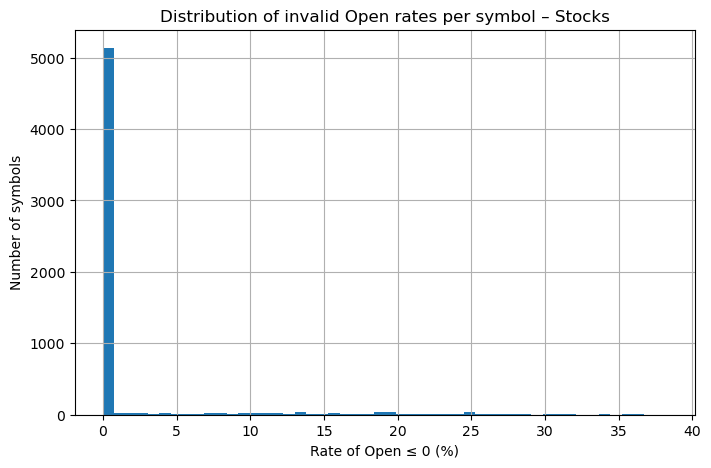


📊 Key quantiles of Open≤0 rate for Stocks:
0.50     0.000000
0.75     0.000000
0.90     7.644321
0.95    18.402887
0.99    28.467856
dtype: float64

📈 Suggested threshold (top 5% worst symbols): 18.40%

🚨 Top 10 symbols with highest invalid Open rates (Stocks):
Symbol
GV      38.260419
CUO     37.007742
SGC     36.629081
NBR     36.612252
NWN     36.272613
OTTR    36.233591
MTZ     35.880175
FUL     35.812858
EGP     35.796028
MKC     35.796028
dtype: float64


In [7]:
from src.utils.data_inspection import analyze_open_zero_distribution

# For stocks
stocks_analysis = analyze_open_zero_distribution(stocks, dataset_name="Stocks")

stocks_rates = stocks_analysis["rates"]



In [9]:
rate_open_le_zero_by_symbol(etfs)

CEF: 16.54%
AAAU: nan%
AADR: nan%
AAXJ: nan%
ABEQ: nan%
ACES: nan%
ACIO: nan%
ACSG: nan%
ACSI: nan%
ACT: nan%
ACWF: nan%
ACWI: nan%
ACWV: nan%
ACWX: nan%
ADME: nan%
ADRE: nan%
AESR: nan%
AFIF: nan%
AFK: nan%
AFLG: nan%
AFMC: nan%
AFSM: nan%
AFTY: nan%
AGG: nan%
AGGP: nan%
AGGY: nan%
AGND: nan%
AGQ: nan%
AGT: nan%
AGZ: nan%
AGZD: nan%
AIA: nan%
AIEQ: nan%
AIIQ: nan%
AIQ: nan%
AIRR: nan%
ALFA: nan%
ALTS: nan%
ALTY: nan%
AMCA: nan%
AMLP: nan%
AMOM: nan%
AMZA: nan%
ANGL: nan%
AOA: nan%
AOK: nan%
AOM: nan%
AOR: nan%
ARCM: nan%
ARGT: nan%
ARKF: nan%
ARKG: nan%
ARKK: nan%
ARKQ: nan%
ARKW: nan%
ARMR: nan%
ASEA: nan%
ASET: nan%
ASHR: nan%
ASHS: nan%
ASHX: nan%
AUSF: nan%
AVDE: nan%
AVDV: nan%
AVEM: nan%
AVUS: nan%
AVUV: nan%
AWAY: nan%
AWTM: nan%
AXJL: nan%
BAB: nan%
BAPR: nan%
BATT: nan%
BAUG: nan%
BBAX: nan%
BBC: nan%
BBCA: nan%
BBEU: nan%
BBH: nan%
BBIN: nan%
BBJP: nan%
BBP: nan%
BBRE: nan%
BBSA: nan%
BBUS: nan%
BCD: nan%
BCI: nan%
BDCY: nan%
BDEC: nan%
BDRY: nan%
BFEB: nan%
BFIT: nan%
BFOR:

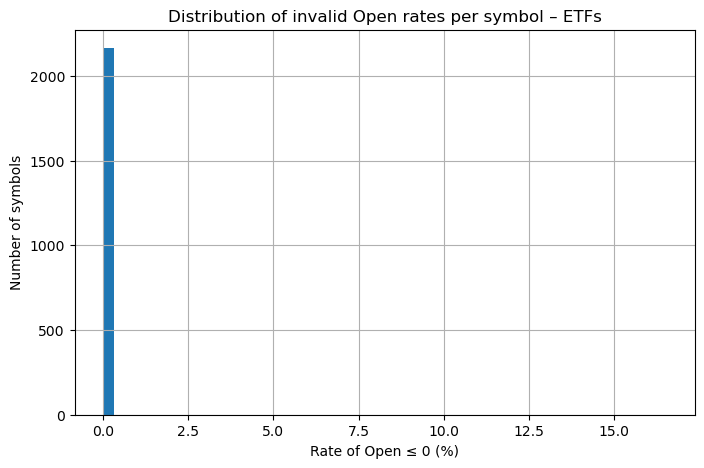


📊 Key quantiles of Open≤0 rate for ETFs:
0.50    0.0
0.75    0.0
0.90    0.0
0.95    0.0
0.99    0.0
dtype: float64

📈 Suggested threshold (top 5% worst symbols): 0.00%

🚨 Top 10 symbols with highest invalid Open rates (ETFs):
Symbol
CEF     16.538282
AAAU     0.000000
PPSC     0.000000
PSCD     0.000000
PSCC     0.000000
PSC      0.000000
PRNT     0.000000
PRN      0.000000
PRFZ     0.000000
PRF      0.000000
dtype: float64


In [11]:
# For etfs
etfs_analysis = analyze_open_zero_distribution(etfs, dataset_name="ETFs")

etfs_rates = etfs_analysis["rates"]


In [21]:
from src.utils.data_inspection import analyze_open_zero_distribution
from src.utils.data_cleaning import clean_market_dataframe


# Choose the threshold 18.4 from the 95th percentile 
thr = 18.4

# 2) Clean using the precomputed rates
stocks_clean_res = clean_market_dataframe(
    stocks,
    open_rate_threshold=thr,
    precomputed_open_rates=stocks_analysis["rates"],
)


stocks_cleaned = stocks_clean_res["df"]


stocks_clean_res["report"], stocks_clean_res["dropped_symbols"][:10]



({'rows_dropped_nan_core_cols': 649,
  'rows_dropped_highlow_le_zero': 36,
  'rows_imputed_adj_close': 0,
  'rows_dropped_unfixable_adj_close': 17168,
  'symbols_dropped_open_rate': 295,
  'rows_imputed_open_from_prev_close': 21053666,
  'rows_dropped_unfixable_open': 514},
 ['AE', 'AEM', 'AGYS', 'ALX', 'AMOT', 'ANAT', 'AP', 'ASNA', 'ASYS', 'AVA'])

In [22]:
stocks_verified = invalids_summary(stocks_cleaned)  
stocks_verified.head()





,Negative volumes,Open price <= 0,Close price <= 0,Adj Close <= 0,High <= 0,Low <= 0,Duplicates,Missing Open,Missing Close,Missing Adj Close,Missing High,Missing Low,Missing Volume
TOTAL,0,0,0,0,0,0,0,0,0,0,0,0,0


In [20]:
# Choose the threshold 0.0 from the 95th percentile 
thr_etf = 0.0

# 2) Clean using the precomputed rates
etfs_clean_res = clean_market_dataframe(
    etfs,
    open_rate_threshold=thr_etf,
    precomputed_open_rates=etfs_analysis["rates"],
)


etfs_cleaned = etfs_clean_res["df"]


etfs_clean_res["report"], etfs_clean_res["dropped_symbols"][:10]


({'rows_dropped_nan_core_cols': 34,
  'rows_dropped_highlow_le_zero': 23,
  'rows_imputed_adj_close': 0,
  'rows_dropped_unfixable_adj_close': 1058,
  'symbols_dropped_open_rate': 1,
  'rows_imputed_open_from_prev_close': 3944576,
  'rows_dropped_unfixable_open': 0},
 ['CEF'])

In [23]:
etfs_verified = invalids_summary(etfs_cleaned)  
etfs_verified.head()

,Negative volumes,Open price <= 0,Close price <= 0,Adj Close <= 0,High <= 0,Low <= 0,Duplicates,Missing Open,Missing Close,Missing Adj Close,Missing High,Missing Low,Missing Volume
TOTAL,0,0,0,0,0,0,0,0,0,0,0,0,0
